In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### Carregar os dados

In [ ]:
def load_station(estacao):
    path = f"/content/dados_{estacao}_H_2025-01-01_2025-12-31.csv"

    df = pd.read_csv(
        path,
        sep=";",
        skiprows=9,
        decimal=","
    )

    df['Hora Medicao'] = (
        df['Hora Medicao']
        .astype(str)
        .str.zfill(4)
    )

    df['time'] = (
        df['Hora Medicao'].str[:2] + ":00:00"
    )

    df = df.rename(columns={
        "Data Medicao": "date"
    })

    df['data_hora_utc'] = pd.to_datetime(
        df['date'] + ' ' + df['time'],
        format='%Y-%m-%d %H:%M:%S'
    )

    df = df.drop(
        columns=[
            'date',
            'time',
            'Hora Medicao'
        ],
        errors='ignore'
    )

    df = (
        df.sort_values('data_hora_utc')
        .reset_index(drop=True)
    )

    return df

In [ ]:
df_prudente = load_station('A707')
df_valparaiso = load_station('A734')

In [ ]:
colunas = [
        'data_hora_utc',
        'UMIDADE RELATIVA DO AR, HORARIA(%)',
    ]

In [ ]:
df_dracena = df_dracena[colunas]
df_prudente = df_prudente[colunas]
df_valparaiso = df_valparaiso[colunas]

In [ ]:
df_valparaiso.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 2 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   data_hora_utc                       8760 non-null   datetime64[ns]
 1   UMIDADE RELATIVA DO AR, HORARIA(%)  8750 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 137.0 KB


In [ ]:
df_final = pd.read_csv('/content/dracena_dados_final.csv')

In [ ]:
df_final.head()

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
0,2025-01-01 00:00:00,26.2,69.0,1.7,965.1,0.0,0.000000
1,2025-01-01 01:00:00,25.1,71.0,2.3,965.7,0.0,0.000000
2,2025-01-01 02:00:00,25.2,70.0,1.7,966.4,0.0,0.016689
3,2025-01-01 03:00:00,25.2,71.0,1.8,966.4,0.0,0.055790
4,2025-01-01 04:00:00,24.4,78.0,1.5,966.1,0.0,0.017643


### Umidade

In [ ]:
df_final['UMIDADE RELATIVA DO AR, HORARIA(%)'].isna().sum()

np.int64(505)

In [ ]:
print(df_final['data_hora_utc'].min())
print(df_final['data_hora_utc'].max())
print(df_final['data_hora_utc'].head())
print(df_final['data_hora_utc'].tail())

2025-01-01 00:00:00
2025-12-31 23:00:00
0    2025-01-01 00:00:00
1    2025-01-01 01:00:00
2    2025-01-01 02:00:00
3    2025-01-01 03:00:00
4    2025-01-01 04:00:00
Name: data_hora_utc, dtype: object
8755    2025-12-31 19:00:00
8756    2025-12-31 20:00:00
8757    2025-12-31 21:00:00
8758    2025-12-31 22:00:00
8759    2025-12-31 23:00:00
Name: data_hora_utc, dtype: object


In [ ]:
COL_UMIDADE = 'UMIDADE RELATIVA DO AR, HORARIA(%)'

df_final['data_hora_utc'] = pd.to_datetime(df_final['data_hora_utc'])
df_prudente['data_hora_utc'] = pd.to_datetime(df_prudente['data_hora_utc'])
df_valparaiso['data_hora_utc'] = pd.to_datetime(df_valparaiso['data_hora_utc'])

In [ ]:
prudente_aux = df_prudente[
    ['data_hora_utc', COL_UMIDADE]
].rename(columns={
    COL_UMIDADE: 'umidade_prudente'
})

valparaiso_aux = df_valparaiso[
    ['data_hora_utc', COL_UMIDADE]
].rename(columns={
    COL_UMIDADE: 'umidade_valparaiso'
})

In [ ]:
df_final = (
    df_final
    .merge(
        prudente_aux,
        on='data_hora_utc',
        how='left',
        validate='one_to_one'
    )
    .merge(
        valparaiso_aux,
        on='data_hora_utc',
        how='left',
        validate='one_to_one'
    )
)

In [ ]:
df_final[
    [
        'data_hora_utc',
        COL_UMIDADE,
        'umidade_prudente',
        'umidade_valparaiso'
    ]
].head()

,data_hora_utc,"UMIDADE RELATIVA DO AR, HORARIA(%)",umidade_prudente,umidade_valparaiso
0,2025-01-01 00:00:00,69.0,66.0,77.0
1,2025-01-01 01:00:00,71.0,66.0,75.0
2,2025-01-01 02:00:00,70.0,67.0,73.0
3,2025-01-01 03:00:00,71.0,65.0,82.0
4,2025-01-01 04:00:00,78.0,66.0,78.0


In [ ]:
PESO_VALPARAISO = 0.523
PESO_PRUDENTE = 0.477

df_final['umidade_idw'] = (
    PESO_VALPARAISO * df_final['umidade_valparaiso']
    +
    PESO_PRUDENTE * df_final['umidade_prudente']
)

In [ ]:
mask_so_valparaiso = (
    df_final['umidade_valparaiso'].notna()
    & df_final['umidade_prudente'].isna()
)

mask_so_prudente = (
    df_final['umidade_valparaiso'].isna()
    & df_final['umidade_prudente'].notna()
)

df_final.loc[
    mask_so_valparaiso,
    'umidade_idw'
] = df_final.loc[
    mask_so_valparaiso,
    'umidade_valparaiso'
]

df_final.loc[
    mask_so_prudente,
    'umidade_idw'
] = df_final.loc[
    mask_so_prudente,
    'umidade_prudente'
]

In [ ]:
mask_missing = df_final[COL_UMIDADE].isna()

print("NaNs antes:", mask_missing.sum())

NaNs antes: 505


In [ ]:
df_final.loc[
    mask_missing,
    COL_UMIDADE
] = df_final.loc[
    mask_missing,
    'umidade_idw'
]

In [ ]:
print(
    "NaNs depois:",
    df_final[COL_UMIDADE].isna().sum()
)

print(
    "Valores imputados:",
    (
        mask_missing
        & df_final[COL_UMIDADE].notna()
    ).sum()
)

NaNs depois: 1
Valores imputados: 504


In [ ]:
df_final = df_final.drop(
    columns=[
        'umidade_prudente',
        'umidade_valparaiso',
        'umidade_idw'
    ]
)

In [ ]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 6 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   data_hora_utc                                         8760 non-null   datetime64[ns]
 1   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           8749 non-null   float64       
 2   UMIDADE RELATIVA DO AR, HORARIA(%)                    8760 non-null   float64       
 3   PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)  8751 non-null   float64       
 4   Radiação (Wh/m2)                                      8760 non-null   float64       
 5   PRECIPITACAO ERA5, HORARIA(mm)                        8760 non-null   float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 410.8 KB


In [ ]:
COL_VENTO = 'VENTO, VELOCIDADE HORARIA(m/s)'

df_final = df_final.drop(columns=[COL_VENTO])

In [ ]:
COL_UMIDADE = 'UMIDADE RELATIVA DO AR, HORARIA(%)'

df_final.loc[
    df_final[COL_UMIDADE].isna(),
    ['data_hora_utc', COL_UMIDADE]
]

,data_hora_utc,"UMIDADE RELATIVA DO AR, HORARIA(%)"
8553,2025-12-23 09:00:00,NaN


In [ ]:
idx = df_final[df_final[COL_UMIDADE].isna()].index[0]

df_final.loc[
    max(0, idx - 3):min(len(df_final) - 1, idx + 3),
    ['data_hora_utc', COL_UMIDADE]
]

,data_hora_utc,"UMIDADE RELATIVA DO AR, HORARIA(%)"
8550,2025-12-23 06:00:00,77.190052
8551,2025-12-23 07:00:00,76.254640
8552,2025-12-23 08:00:00,75.878248
8553,2025-12-23 09:00:00,NaN
8554,2025-12-23 10:00:00,71.311804
8555,2025-12-23 11:00:00,64.186340
8556,2025-12-23 12:00:00,57.186340


interpolação temporal/linear entre as horas adjacentes, não a média de 2025:

In [ ]:
df_final[COL_UMIDADE] = (
    df_final[COL_UMIDADE]
    .interpolate(method='linear', limit=1)
)

In [ ]:
df_final.loc[
    df_final['data_hora_utc'] == pd.Timestamp('2025-12-23 09:00:00'),
    ['data_hora_utc', COL_UMIDADE]
]

,data_hora_utc,"UMIDADE RELATIVA DO AR, HORARIA(%)"
8553,2025-12-23 09:00:00,73.595026


### Temperatura 11 Nulos

In [ ]:
COL_TEMP = 'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)'

temp_prudente = df_prudente[
    ['data_hora_utc', COL_TEMP]
].rename(columns={
    COL_TEMP: 'temperatura_prudente'
})

temp_valparaiso = df_valparaiso[
    ['data_hora_utc', COL_TEMP]
].rename(columns={
    COL_TEMP: 'temperatura_valparaiso'
})

In [ ]:
df_final = (
    df_final
    .merge(
        temp_prudente,
        on='data_hora_utc',
        how='left',
        validate='one_to_one'
    )
    .merge(
        temp_valparaiso,
        on='data_hora_utc',
        how='left',
        validate='one_to_one'
    )
)

In [ ]:
PESO_VALPARAISO = 0.523
PESO_PRUDENTE = 0.477

df_final['temperatura_idw'] = (
    PESO_VALPARAISO * df_final['temperatura_valparaiso']
    +
    PESO_PRUDENTE * df_final['temperatura_prudente']
)

In [ ]:
mask_so_valparaiso = (
    df_final['temperatura_valparaiso'].notna()
    & df_final['temperatura_prudente'].isna()
)

mask_so_prudente = (
    df_final['temperatura_valparaiso'].isna()
    & df_final['temperatura_prudente'].notna()
)

df_final.loc[
    mask_so_valparaiso,
    'temperatura_idw'
] = df_final.loc[
    mask_so_valparaiso,
    'temperatura_valparaiso'
]

df_final.loc[
    mask_so_prudente,
    'temperatura_idw'
] = df_final.loc[
    mask_so_prudente,
    'temperatura_prudente'
]

In [ ]:
mask_temp_missing = df_final[COL_TEMP].isna()

print("NaNs antes:", mask_temp_missing.sum())

df_final.loc[
    mask_temp_missing,
    [
        'data_hora_utc',
        COL_TEMP,
        'temperatura_valparaiso',
        'temperatura_prudente',
        'temperatura_idw'
    ]
]

NaNs antes: 11


,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",temperatura_valparaiso,temperatura_prudente,temperatura_idw
6884,2025-10-14 20:00:00,NaN,NaN,29.1,29.1
7072,2025-10-22 16:00:00,NaN,NaN,26.8,26.8
7073,2025-10-22 17:00:00,NaN,NaN,28.1,28.1
7074,2025-10-22 18:00:00,NaN,NaN,28.2,28.2
7075,2025-10-22 19:00:00,NaN,NaN,28.6,28.6
7076,2025-10-22 20:00:00,NaN,NaN,28.1,28.1
7077,2025-10-22 21:00:00,NaN,NaN,26.8,26.8
7078,2025-10-22 22:00:00,NaN,NaN,25.3,25.3
7188,2025-10-27 12:00:00,NaN,21.5,NaN,21.5
8055,2025-12-02 15:00:00,NaN,29.7,NaN,29.7


In [ ]:
df_final.loc[
    mask_temp_missing,
    COL_TEMP
] = df_final.loc[
    mask_temp_missing,
    'temperatura_idw'
]

In [ ]:
print(
    "NaNs depois:",
    df_final[COL_TEMP].isna().sum()
)

print(
    "Valores imputados:",
    (
        mask_temp_missing
        & df_final[COL_TEMP].notna()
    ).sum()
)

NaNs depois: 1
Valores imputados: 10


In [ ]:
df_final = df_final.drop(
    columns=[
        'temperatura_prudente',
        'temperatura_valparaiso',
        'temperatura_idw'
    ]
)

In [ ]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 6 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   data_hora_utc                                         8760 non-null   datetime64[ns]
 1   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           8759 non-null   float64       
 2   UMIDADE RELATIVA DO AR, HORARIA(%)                    8760 non-null   float64       
 3   PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)  8751 non-null   float64       
 4   Radiação (Wh/m2)                                      8760 non-null   float64       
 5   PRECIPITACAO ERA5, HORARIA(mm)                        8760 non-null   float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 410.8 KB


In [ ]:
COL_TEMP = 'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)'

idx = df_final[df_final[COL_TEMP].isna()].index[0]

df_final.loc[
    idx-3:idx+3,
    ['data_hora_utc', COL_TEMP]
]

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)"
8550,2025-12-23 06:00:00,24.236897
8551,2025-12-23 07:00:00,23.992799
8552,2025-12-23 08:00:00,23.899258
8553,2025-12-23 09:00:00,NaN
8554,2025-12-23 10:00:00,25.568820
8555,2025-12-23 11:00:00,27.500000
8556,2025-12-23 12:00:00,29.243727


In [ ]:
df_final[COL_TEMP] = (
    df_final[COL_TEMP]
    .interpolate(method='linear', limit=1)
)

In [ ]:
df_final.loc[
    df_final['data_hora_utc'] == pd.Timestamp('2025-12-23 09:00:00'),
    ['data_hora_utc', COL_TEMP]
]

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)"
8553,2025-12-23 09:00:00,24.734039


In [ ]:
df_final[COL_TEMP].isna().sum()

np.int64(0)

### Pressão

In [ ]:
COL_PRESSAO = 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)'

pressao_valparaiso = df_valparaiso[
    ['data_hora_utc', COL_PRESSAO]
].rename(columns={
    COL_PRESSAO: 'pressao_valparaiso'
})

In [ ]:
df_final = df_final.merge(
    pressao_valparaiso,
    on='data_hora_utc',
    how='left',
    validate='one_to_one'
)

In [ ]:
mask_pressao_missing = df_final[COL_PRESSAO].isna()

print("NaNs antes:", mask_pressao_missing.sum())

df_final.loc[
    mask_pressao_missing,
    [
        'data_hora_utc',
        COL_PRESSAO,
        'pressao_valparaiso'
    ]
]

NaNs antes: 9


,data_hora_utc,"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",pressao_valparaiso
6884,2025-10-14 20:00:00,NaN,NaN
7072,2025-10-22 16:00:00,NaN,NaN
7073,2025-10-22 17:00:00,NaN,NaN
7074,2025-10-22 18:00:00,NaN,NaN
7075,2025-10-22 19:00:00,NaN,NaN
7076,2025-10-22 20:00:00,NaN,NaN
7077,2025-10-22 21:00:00,NaN,NaN
7078,2025-10-22 22:00:00,NaN,NaN
8553,2025-12-23 09:00:00,NaN,NaN




*   14/10 20h → lacuna isolada → interpolação linear é tranquila.
*   22/10 16h–22h → bloco de 7 horas → eu não interpolaria cegamente.
*   23/12 09h → lacuna isolada → interpolação linear é tranquila.





Lacunas isoladas (14/10 20h e 23/12 09h): interpolação linear entre as horas adjacentes.
Bloco de 7 horas de 22/10: primeiro examine a pressão algumas horas antes e depois. Se houver comportamento suave, use interpolação temporal linear. Sete horas não é absurdo para uma variável relativamente suave como pressão, mas precisamos verificar visualmente antes.

In [ ]:
inicio = pd.Timestamp('2025-10-22 08:00:00')
fim = pd.Timestamp('2025-10-23 06:00:00')

trecho = df_final.loc[
    df_final['data_hora_utc'].between(inicio, fim),
    ['data_hora_utc', COL_PRESSAO]
]

trecho

,data_hora_utc,"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)"
7064,2025-10-22 08:00:00,975.1
7065,2025-10-22 09:00:00,975.7
7066,2025-10-22 10:00:00,976.3
7067,2025-10-22 11:00:00,977.3
7068,2025-10-22 12:00:00,977.7
7069,2025-10-22 13:00:00,977.9
7070,2025-10-22 14:00:00,977.9
7071,2025-10-22 15:00:00,977.5
7072,2025-10-22 16:00:00,NaN
7073,2025-10-22 17:00:00,NaN


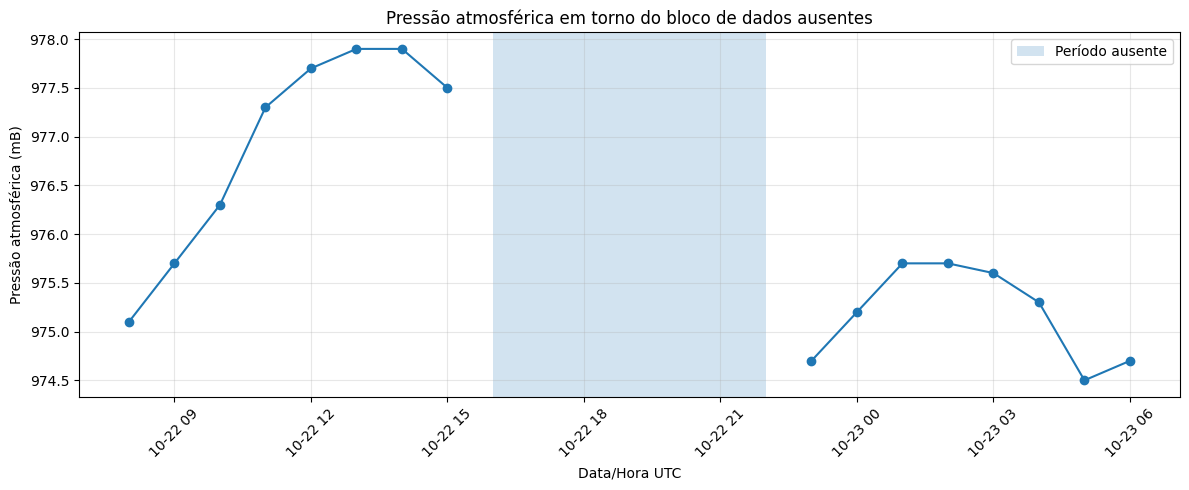

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    trecho['data_hora_utc'],
    trecho[COL_PRESSAO],
    marker='o'
)

plt.axvspan(
    pd.Timestamp('2025-10-22 16:00:00'),
    pd.Timestamp('2025-10-22 22:00:00'),
    alpha=0.2,
    label='Período ausente'
)

plt.xlabel('Data/Hora UTC')
plt.ylabel('Pressão atmosférica (mB)')
plt.title('Pressão atmosférica em torno do bloco de dados ausentes')
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

O gráfico mostra uma evolução suave da pressão antes e depois da lacuna. Às 15h temos 977,5 mB e às 23h 974,7 mB; portanto, a interpolação vai representar uma queda gradual entre esses pontos, em vez de criar um valor constante artificial com média/mediana

In [ ]:
df_final.loc[
    df_final['data_hora_utc'].between(
        '2025-10-22 12:00:00',
        '2025-10-23 02:00:00'
    ),
    ['data_hora_utc', COL_PRESSAO]
]

,data_hora_utc,"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)"
7068,2025-10-22 12:00:00,977.7
7069,2025-10-22 13:00:00,977.9
7070,2025-10-22 14:00:00,977.9
7071,2025-10-22 15:00:00,977.5
7072,2025-10-22 16:00:00,NaN
7073,2025-10-22 17:00:00,NaN
7074,2025-10-22 18:00:00,NaN
7075,2025-10-22 19:00:00,NaN
7076,2025-10-22 20:00:00,NaN
7077,2025-10-22 21:00:00,NaN


In [ ]:
COL_PRESSAO = 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)'

print("NaNs antes:", df_final[COL_PRESSAO].isna().sum())

df_final[COL_PRESSAO] = (
    df_final[COL_PRESSAO]
    .interpolate(
        method='linear',
        limit=7,
        limit_area='inside'
    )
)

print("NaNs depois:", df_final[COL_PRESSAO].isna().sum())

NaNs antes: 9
NaNs depois: 0


In [ ]:
df_final.loc[
    df_final['data_hora_utc'].between(
        '2025-10-22 14:00:00',
        '2025-10-23 00:00:00'
    ),
    ['data_hora_utc', COL_PRESSAO]
]

,data_hora_utc,"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)"
7070,2025-10-22 14:00:00,977.90
7071,2025-10-22 15:00:00,977.50
7072,2025-10-22 16:00:00,977.15
7073,2025-10-22 17:00:00,976.80
7074,2025-10-22 18:00:00,976.45
7075,2025-10-22 19:00:00,976.10
7076,2025-10-22 20:00:00,975.75
7077,2025-10-22 21:00:00,975.40
7078,2025-10-22 22:00:00,975.05
7079,2025-10-22 23:00:00,974.70


8 intervalos entre 15h (977.5) e 23h (974.7)

$$\frac{974.7 - 977.5}{8} = -0.35 \text{ mB/h}$$


valores imputados por interpolação temporal linear, assumindo continuidade entre as observaçoes adjacentes

In [ ]:
df_final[COL_PRESSAO].isna().sum()

np.int64(0)

## Df final tratado sem nulos

In [ ]:
df_final.to_csv(
    '/content/df_final_2025_tratado.csv',
    index=False,
    encoding='utf-8-sig'
)